In [1]:
import random
import cobra
import escher
import pandas as pd
import numpy as np
import json
import csv
from cobra.io import save_json_model
from cobra import Reaction
from collections import Counter
from cobra.flux_analysis.loopless import add_loopless, loopless_solution
import matplotlib.pyplot as plt
from cobra.flux_analysis import moma
import time

In [2]:
cobra.Configuration().solver = "gurobi"

In [3]:
#model_path = 'models/iMT1026v3.xml'
model_path = 'models/iMT1026v3jup.xml'
#model_path = 'iPichia.xml'

model = cobra.io.read_sbml_model(model_path)

model

Set parameter Username
Academic license - for non-commercial use only - expires 2027-09-18


Name,iMT1026v3
Memory address,23a613af148
Number of metabolites,1706
Number of reactions,2237
Number of genes,1026
Number of groups,77
Objective expression,1.0*Ex_biomass - 1.0*Ex_biomass_reverse_5354f
Compartments,"Vacuole, Cytosol, Mitochondria, Peroxisome, Extracellular space, Endoplasmic Reticulum, Golgi Apparatus, Nucleus, Mitochondrial intermembrane space"


In [4]:
model.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
glyc_e,Ex_glyc,0.9538,3,100.00%
nh4_e,Ex_nh4,0.3009,0,0.00%
o2_e,Ex_o2,1.616,0,0.00%
pi_e,Ex_pi,0.0122,0,0.00%
so4_e,Ex_so4,0.002128,0,0.00%
Metabolite,Reaction,Flux,C-Number,C-Flux
biomass_e,Ex_biomass,-0.04851,0,0.00%
co2_e,Ex_co2,-1.163,1,100.00%
h_e,Ex_h,-0.3153,0,0.00%
h2o_e,Ex_h2o,-2.735,0,0.00%


In [5]:
# Change grwoth on glycerol to growth on 60% glucose and 40% methanol
# Add reaction describing this growth

biomass_gly = model.reactions.get_by_id('BIOMASS_glyc')
biomass_gly.bounds = (0,0)
biomass_gly

carbs = model.metabolites.get_by_id('CARBOHYDRATES_c')
DNA = model.metabolites.get_by_id('DNA_c')
lipids = model.metabolites.get_by_id('LIPIDS_c')
prot = model.metabolites.get_by_id('PROTEIN_c')
RNA = model.metabolites.get_by_id('RNA_c')
atp = model.metabolites.get_by_id('atp_c')
cof = model.metabolites.get_by_id('cof_c')
h2o = model.metabolites.get_by_id('h2o_c')
adp = model.metabolites.get_by_id('adp_c')
biomass = model.metabolites.get_by_id('biomass_c')
h = model.metabolites.get_by_id('h_c')
pi = model.metabolites.get_by_id('pi_c')

biomass_glc_meoh = Reaction ('biomass_glc_meoh_60/40')
biomass_glc_meoh.name = 'Biomass composition (g/g) - 60/40 Glucose/Methanol'
biomass_glc_meoh.add_metabolites({carbs: -0.33,
                                   DNA: -0.001,
                                   lipids: -0.042,
                                   prot: -0.49,
                                   RNA: -0.058,
                                   atp: -63.85,
                                   cof: -1,
                                   h2o: -63.85,
                                   adp: 63.85,
                                   pi: 63.85,
                                   biomass: 1,
                                   h: 63.85})
biomass_glc_meoh

Reaction identifier,biomass_glc_meoh_60/40
Name,Biomass composition (g/g) - 60/40 Glucose/Methanol
Memory address,0x23a27211408
Stoichiometry,0.33 CARBOHYDRATES_c + 0.001 DNA_c + 0.042 LIPIDS_c + 0.49 PROTEIN_c + 0.058 RNA_c + 63.85 atp_c + cof_c + 63.85 h2o_c --> 63.85 adp_c + biomass_c + 63.85 h_c + 63.85 pi_c 0.33 Carbohydrates + 0.001 DNA + 0.042 Lipids + 0.49 PROTEIN + 0.058 RNA + 63.85 ATP + Cofactors and small molecules + 63.85 H2O --> 63.85 ADP + Biomass + 63.85 H+ + 63.85 Phosphate
GPR,
Lower bound,0.0
Upper bound,1000.0


In [6]:
# Add new biomass reaction to the model

print (len(model.reactions))
model.add_reactions([biomass_glc_meoh])
print (len(model.reactions))

2237
2238


In [7]:
#Tanquem l'entrada de Glicerol
glycerol_exchange = model.exchanges.get_by_id('Ex_glyc')
glycerol_exchange.bounds = (0,0)
glycerol_exchange

Reaction identifier,Ex_glyc
Name,Glycerol exchange
Memory address,0x23a3053bfc8
Stoichiometry,glyc_e --> Glycerol -->
GPR,
Lower bound,0
Upper bound,0


In [8]:
# Add qmeoh constraints observed in chemostat cultivations
methanol_exchange = model.exchanges.get_by_id('Ex_meoh')
methanol_exchange.bounds = (-1.24, -1.18)
methanol_exchange

Reaction identifier,Ex_meoh
Name,Methanol exchange
Memory address,0x23a305447c8
Stoichiometry,meoh_e <-- Methanol <--
GPR,
Lower bound,-1.24
Upper bound,-1.18


In [9]:
# Add qgluc constraints observed in chemostat cultivations
glucose_exchange = model.reactions.get_by_id('Ex_glc_D')
glucose_exchange.bounds = (-0.72, -0.7)
glucose_exchange

Reaction identifier,Ex_glc_D
Name,D-Glucose exchange
Memory address,0x23a3051df48
Stoichiometry,glc_D_e <-- D-Glucose <--
GPR,
Lower bound,-0.72
Upper bound,-0.7


In [10]:
# Change the reactions for the synthesis of lipids, proteins and sterols from glycerol to those from glucose

model.reactions.get_by_id('LIPIDS_glyc').bounds = (0,0)
model.reactions.get_by_id('PROTEINS_glyc').bounds = (0,0)
model.reactions.get_by_id('STEROLS_glyc').bounds = (0,0)

# note: these reactions from glucose do not have the glucose specification
model.reactions.get_by_id('LIPIDS').bounds = (0,1000)
model.reactions.get_by_id('PROTEINS').bounds = (0,1000)
model.reactions.get_by_id('STEROLS').bounds = (0,1000)

In [11]:
# ATP maintenance requirement (NGAME = Non-Growth Associated Maintenance Energy) based on previous studies on 
# the growth of X33-ROL on Gluc/MeOH from the group (Eric's Master Thesis)

model.reactions.get_by_id('ATPM').bounds = (1.96, 1000)

In [12]:
rolAA = model.reactions.get_by_id('rolAA')
rolAA.bounds = (0,1000)
rolRNA = model.reactions.get_by_id('rolRNA')
rolRNA.bounds = (0,1000)
rolDNA = model.reactions.get_by_id('rolDNA')
rolDNA.bounds = (0,1000)
pROL = model.reactions.get_by_id('pROL')
pROL.bounds = (0,1000)
Rol_transport =  model.reactions.get_by_id('ROLt')
Rol_transport.bounds = (0,1000)
ROL_exchange = model.exchanges.get_by_id('Ex_rol')
#ROL_exchange.bounds = (0.0003773,1000)
ROL_exchange.bounds = (0,0)

pFAB = model.reactions.get_by_id('pFAB')
pFAB.bounds = (0,0)
fabAA = model.reactions.get_by_id('fabAA')
fabAA.bounds = (0,0)
fabt = model.reactions.get_by_id('fabt')
fabt.bounds = (0,0)
fabRNA = model.reactions.get_by_id('fabRNA')
fabRNA.bounds = (0,0)
fabDNA = model.reactions.get_by_id('fabDNA')
FAB_exchange = model.exchanges.get_by_id('Ex_fab')
FAB_exchange.bounds = (0,0)


# Extra reactions that must be closed for simulations to run smoothly:

APAT2r = model.reactions.get_by_id('APAT2r')
APAT2r.bounds = (0,0) # reaction not present in Pichia, it is yet to be removed from the model

MMSAD3 = model.reactions.get_by_id('MMSAD3')
MMSAD3.bounds = (0,0) # The reduction reaction of MSA into Acetil-CoA it is due to an unspecific effect. Reaction
# under evaluation of being kept or not.

In [13]:
pfba_WT = cobra.flux_analysis.pfba(model)

In [14]:
WT_growth = pfba_WT.fluxes['Ex_biomass']

In [15]:
WT_growth

0.09653219460929795

In [16]:
# NADPH turnover rate WT strain
nadph_c = model.metabolites.get_by_id('nadph_c')

positive_nadph_flux_sum_WT = 0.0
for reaction in nadph_c.reactions:
    flux = pfba_WT.fluxes[reaction.id]
    coef = reaction.get_coefficient(nadph_c)
    positive_nadph_flux_sum_WT += abs(flux*coef)
    

print (positive_nadph_flux_sum_WT/2)

0.8739408926222877


In [17]:
ROL_exchange.bounds = (0.003, 1000)

In [18]:
pfba_ROL = cobra.flux_analysis.pfba(model)

In [19]:
ROL_growth = pfba_ROL.fluxes['Ex_biomass']

In [20]:
ROL_growth

0.09340743007227764

In [21]:
ROL_baseProd = pfba_ROL.fluxes['Ex_rol']

In [22]:
# NADPH turnover rate WT strain
nadph_c = model.metabolites.get_by_id('nadph_c')

positive_nadph_flux_sum_WT = 0.0
for reaction in nadph_c.reactions:
    flux = pfba_ROL.fluxes[reaction.id]
    coef = reaction.get_coefficient(nadph_c)
    positive_nadph_flux_sum_WT += abs(flux*coef)
    

print (positive_nadph_flux_sum_WT/2)

0.8859193257483108


In [23]:
ROL_exchange.bounds = (0, 1000)

In [24]:
fba_WT = model.optimize()

In [25]:
fba_WT.fluxes['Ex_biomass']

0.09653219359788659

In [26]:
fba_WT.fluxes['Ex_rol']

0.0

In [27]:
# NADPH turnover rate WT strain
nadph_c = model.metabolites.get_by_id('nadph_c')

positive_nadph_flux_sum_WT = 0.0
for reaction in nadph_c.reactions:
    flux = fba_WT.fluxes[reaction.id]
    coef = reaction.get_coefficient(nadph_c)
    positive_nadph_flux_sum_WT += abs(flux*coef)
    

print (positive_nadph_flux_sum_WT/2)

0.8739408834656122


In [28]:
def calculate_nadph_turnover(model, solution):

    nadph_c = model.metabolites.get_by_id("nadph_c")

    nadph_turnover = 0.0

    for reaction in nadph_c.reactions:

        flux = solution.fluxes[reaction.id]
        coefficient = reaction.get_coefficient("nadph_c")

        nadph_turnover += abs(flux * coefficient)

    # Divide by 2 to avoid counting both production and
    # consumption as separate contributions to turnover.
    nadph_turnover /= 2

    return nadph_turnover

In [29]:
# ============================================================
# 1. PARAMETERS AND INITIALIZATION
# ============================================================

n_iterations = 30

increase_min = 0.05
increase_max = 0.10

proportional_results = []
absolute_results = []
iteration_metrics = []

nadph_c = model.metabolites.get_by_id("nadph_c")

# ============================================================
# 2. RUN ITERATIONS
# ============================================================

for iteration in range(1, n_iterations + 1):

    with model:

        # ----------------------------------------------------
        # 2.1 Randomly increase NADPH-producing reaction fluxes
        # ----------------------------------------------------

        for reaction in model.reactions:

            nadph_stoich = reaction.metabolites.get(nadph_c, 0)
            reference_flux = pfba_WT.fluxes[reaction.id]

            # Identify reactions producing NADPH in the
            # direction of their reference flux
            if reference_flux * nadph_stoich > 0:

                increase = np.random.uniform(
                    increase_min,
                    increase_max
                )

                target_flux = reference_flux * (1 + increase)

                # Enforce the target as a lower bound
                reaction.lower_bound = target_flux

        # ----------------------------------------------------
        # 2.2 Run MOMA using WT pFBA as the reference
        # ----------------------------------------------------

        moma_result = cobra.flux_analysis.moma(
            model,
            solution=pfba_WT,
            linear=True
        )

        # ----------------------------------------------------
        # 2.3 Calculate NADPH turnover and growth rate
        # ----------------------------------------------------

        nadph_turnover = calculate_nadph_turnover(
            model,
            moma_result
        )

        growth_rate = moma_result.fluxes["Ex_biomass"]

        iteration_metrics.append({
            "Iteration": iteration,
            "NADPH turnover rate": nadph_turnover,
            "Growth rate": growth_rate
        })

        # ----------------------------------------------------
        # 2.4 Calculate reaction-wise changes from WT pFBA
        # ----------------------------------------------------

        reaction_changes = []

        for reaction in model.reactions:

            reaction_id = reaction.id

            reference_flux = pfba_WT.fluxes[reaction_id]
            moma_flux = moma_result.fluxes[reaction_id]

            absolute_change = abs(
                moma_flux - reference_flux
            )

            if abs(reference_flux) > 1e-6:
                proportional_change = (
                    absolute_change / abs(reference_flux)
                )
            else:
                proportional_change = np.nan

            reaction_changes.append({
                "ID": reaction_id,
                "Name": reaction.name,
                "pFBA flux": reference_flux,
                "MOMA flux": moma_flux,
                "Absolute change": absolute_change,
                "Proportional change": proportional_change
            })

        # ----------------------------------------------------
        # 2.5 Identify top 10 proportional changes
        # ----------------------------------------------------

        proportional_changes = sorted(
            [
                r for r in reaction_changes
                if not np.isnan(r["Proportional change"])
            ],
            key=lambda x: x["Proportional change"],
            reverse=True
        )

        proportional_ids = [
            r["ID"] for r in proportional_changes[:10]
        ]

        # Pad with NaN if fewer than 10 reactions are available
        proportional_ids += [
            np.nan
        ] * (10 - len(proportional_ids))

        # ----------------------------------------------------
        # 2.6 Identify top 10 absolute changes
        # ----------------------------------------------------

        absolute_changes = sorted(
            reaction_changes,
            key=lambda x: x["Absolute change"],
            reverse=True
        )

        absolute_ids = [
            r["ID"] for r in absolute_changes[:10]
        ]

        absolute_ids += [
            np.nan
        ] * (10 - len(absolute_ids))

    # The model context has now restored the original bounds.

    # --------------------------------------------------------
    # 2.7 Store results for this iteration
    # --------------------------------------------------------

    proportional_results.append(
        [iteration] + proportional_ids
    )

    absolute_results.append(
        [iteration] + absolute_ids
    )

    print(
        f"Iteration {iteration}/{n_iterations} completed"
    )

# ============================================================
# 3. CREATE DATAFRAMES
# ============================================================

columns = ["Iteration"] + [
    f"Top {i}" for i in range(1, 11)
]

df_proportional = pd.DataFrame(
    proportional_results,
    columns=columns
)

df_absolute = pd.DataFrame(
    absolute_results,
    columns=columns
)

df_metrics = pd.DataFrame(iteration_metrics)

# Display NADPH turnover and growth for each iteration
print("\nNADPH turnover and growth rates:")
print(df_metrics.to_string(index=False))

# ============================================================
# 4. EXPORT ALL RESULTS TO EXCEL
# ============================================================

output_file = "results/RDXMAX_iterations_Growth_NADPH.xlsx"

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    df_proportional.to_excel(
        writer,
        sheet_name="Proportional changes",
        index=False
    )

    df_absolute.to_excel(
        writer,
        sheet_name="Absolute changes",
        index=False
    )

    df_metrics.to_excel(
        writer,
        sheet_name="NADPH and Growth",
        index=False
    )

print(f"\nExcel file created: {output_file}")

Iteration 1/30 completed
Iteration 2/30 completed


C:\Users\Eric\miniconda3\envs\s2m2\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)


Iteration 3/30 completed
Iteration 4/30 completed
Iteration 5/30 completed
Iteration 6/30 completed
Iteration 7/30 completed
Iteration 8/30 completed
Iteration 9/30 completed
Iteration 10/30 completed
Iteration 11/30 completed
Iteration 12/30 completed
Iteration 13/30 completed
Iteration 14/30 completed
Iteration 15/30 completed
Iteration 16/30 completed
Iteration 17/30 completed
Iteration 18/30 completed
Iteration 19/30 completed
Iteration 20/30 completed
Iteration 21/30 completed
Iteration 22/30 completed
Iteration 23/30 completed
Iteration 24/30 completed
Iteration 25/30 completed
Iteration 26/30 completed
Iteration 27/30 completed
Iteration 28/30 completed
Iteration 29/30 completed
Iteration 30/30 completed

NADPH turnover and growth rates:
 Iteration  NADPH turnover rate  Growth rate
         1             0.959486     0.095295
         2             0.946534     0.095509
         3            44.317496     0.105716
         4             0.934390     0.095620
         5          

### The next step is to count the number of times that reactions appear in the lists

In [30]:
from collections import Counter

# Remove the Iteration column
proportional_ids = df_proportional.drop(columns=["Iteration"]).values.flatten()
absolute_ids = df_absolute.drop(columns=["Iteration"]).values.flatten()

# Count occurrences
proportional_counts = Counter(proportional_ids)
absolute_counts = Counter(absolute_ids)

# Convert to DataFrames and sort
df_proportional_counts = pd.DataFrame(
    proportional_counts.items(),
    columns=["Reaction ID", "Occurrences"]
).sort_values(
    "Occurrences",
    ascending=False
)

df_absolute_counts = pd.DataFrame(
    absolute_counts.items(),
    columns=["Reaction ID", "Occurrences"]
).sort_values(
    "Occurrences",
    ascending=False
)

print("\n===== PROPORTIONAL CHANGE FREQUENCY =====\n")
print(df_proportional_counts)

print("\n===== ABSOLUTE CHANGE FREQUENCY =====\n")
print(df_absolute_counts)


===== PROPORTIONAL CHANGE FREQUENCY =====

    Reaction ID  Occurrences
1       PAtm_PP           23
2     DASYNm_PP           22
3         CTPtm           22
6       PStm_PP           22
4         THFtm           21
..          ...          ...
19       ILETAm            1
20       ILEtmi            1
22         ME1m            1
40   ZYMSTAT_PP            1
64  MIPCS326_SC            1

[65 rows x 2 columns]

===== ABSOLUTE CHANGE FREQUENCY =====

     Reaction ID  Occurrences
0         G6PDH2           19
4            RPE           19
9           TALA           19
1            GND           19
3            PGI           19
..           ...          ...
43  ZYMSTESTH_PP            1
18      10FTHFtm            1
19         THFtm            1
40        GLUt7m            1
32        ATPS3m            1

[65 rows x 2 columns]


In [31]:
# Transfer the results into an Excel file
with pd.ExcelWriter(
    "RDXMAX_frecuencies.xlsx",
    engine="openpyxl"
) as writer:

    df_proportional.to_excel(
        writer,
        sheet_name="Proportional changes",
        index=False
    )

    df_absolute.to_excel(
        writer,
        sheet_name="Absolute changes",
        index=False
    )

    df_proportional_counts.to_excel(
        writer,
        sheet_name="Proportional frequency",
        index=False
    )

    df_absolute_counts.to_excel(
        writer,
        sheet_name="Absolute frequency",
        index=False
    )

In [32]:
RDXMAXCandidates = ['RPI','RPE','PGL','PGI','ASPTA','CTPtm','THFtm','PAtm_PP']

In [33]:
nadph_turnover_WT = calculate_nadph_turnover(
    model,
    pfba_WT
)

print("NADPH turnover WT:", nadph_turnover_WT)

NADPH turnover WT: 0.8739408926222877


In [34]:
nadph_results = []

for reaction_id in RDXMAXCandidates:

    reaction = model.reactions.get_by_id(reaction_id)

    wt_flux = pfba_WT.fluxes[reaction_id]

    for intervention_percent in [100, 75, 50, 25, -25, -50, -75, -100]:

        # Calculate intervention target
        target_flux = wt_flux * (
            1 + intervention_percent / 100
        )

        # Save original bounds
        original_bounds = reaction.bounds

        try:

            # Force intervention
            reaction.bounds = (
                target_flux,
                target_flux
            )

            # Keep the same objective as the WT pFBA
            mutant_solution = cobra.flux_analysis.pfba(model)
            if mutant_solution.status == "optimal":

                nadph_turnover = calculate_nadph_turnover(
                    model,
                    mutant_solution
                )

            else:

                nadph_turnover = np.nan

        finally:

            reaction.bounds = original_bounds

        nadph_results.append({
            "Reaction": reaction_id,
            "Intervention": f"{intervention_percent:+.0f}%",
            "WT_Flux": wt_flux,
            "Intervention_Flux": target_flux,
            "NADPH_Turnover_WT": nadph_turnover_WT,
            "NADPH_Turnover_Mutant": nadph_turnover
        })


nadph_results = pd.DataFrame(nadph_results)

print(nadph_results)

   Reaction Intervention   WT_Flux  Intervention_Flux  NADPH_Turnover_WT  \
0       RPI        +100%  0.010341           0.020681           0.873941   
1       RPI         +75%  0.010341           0.018096           0.873941   
2       RPI         +50%  0.010341           0.015511           0.873941   
3       RPI         +25%  0.010341           0.012926           0.873941   
4       RPI         -25%  0.010341           0.007756           0.873941   
..      ...          ...       ...                ...                ...   
59  PAtm_PP         +25%  0.000023           0.000029           0.873941   
60  PAtm_PP         -25%  0.000023           0.000017           0.873941   
61  PAtm_PP         -50%  0.000023           0.000011           0.873941   
62  PAtm_PP         -75%  0.000023           0.000006           0.873941   
63  PAtm_PP        -100%  0.000023           0.000000           0.873941   

    NADPH_Turnover_Mutant  
0                0.894622  
1                0.889452  
2  

In [35]:
RDXMAXCandidates = ['RPI','RPE','PGL','PGI','ASPTA','CTPtm','THFtm','PAtm_PP']
percentages = [25, 50, 75, 100]

results = []
total = len(RDXMAXCandidates) * len(percentages) * 2
run_number = 0

start_time = time.time()

for reaction_id in RDXMAXCandidates:

    reference_flux = pfba_ROL.fluxes[reaction_id]

    for percentage in percentages:

        fraction = percentage / 100

        for intervention, target_flux in [
            ("Overexpression", reference_flux * (1 + fraction)),
            ("Downregulation", reference_flux * (1 - fraction))
        ]:

            run_number += 1
            simulation_start = time.time()

            print(
                f"[{run_number}/{total}] "
                f"{reaction_id} | {intervention} | "
                f"{percentage}% | target={target_flux:.6g}",
                flush=True
            )

            try:
                with model:
                    reaction = model.reactions.get_by_id(reaction_id)
                    reaction.bounds = (target_flux, target_flux)

                    solution = moma(
                        model,
                        solution=pfba_ROL,
                        linear=False
                    )

                    rol_flux = (
                        solution.fluxes["Ex_rol"]
                        if solution.status == "optimal"
                        else np.nan
                    )

                    biomass_flux = (
                        solution.fluxes["Ex_biomass"]
                        if solution.status == "optimal"
                        else np.nan
                    )

                    status = solution.status

            except Exception as e:
                rol_flux = np.nan
                biomass_flux = np.nan
                status = f"Error: {e}"

            elapsed = time.time() - simulation_start

            print(
                f"    Status: {status} | "
                f"ROL: {rol_flux} | "
                f"Time: {elapsed:.2f} s",
                flush=True
            )

            results.append({
                "Reaction": reaction_id,
                "Intervention": intervention,
                "Change_percent": percentage,
                "Reference_flux": reference_flux,
                "Target_flux": target_flux,
                "ROL_production": rol_flux,
                "Biomass": biomass_flux,
                "Status": status,
                "Time_s": elapsed
            })


moma_results = pd.DataFrame(results)

print(f"\nCompleted {len(moma_results)} simulations.")
print(f"Total elapsed time: {time.time() - start_time:.2f} s")

display(moma_results)

[1/64] RPI | Overexpression | 25% | target=0.0128715
    Status: optimal | ROL: 0.003175441208589888 | Time: 15.03 s
[2/64] RPI | Downregulation | 25% | target=0.00772291
    Status: optimal | ROL: 0.0031661077431788492 | Time: 14.85 s
[3/64] RPI | Overexpression | 50% | target=0.0154458
    Status: optimal | ROL: 0.00335057494066715 | Time: 14.17 s
[4/64] RPI | Downregulation | 50% | target=0.00514861
    Status: optimal | ROL: 0.0033319389843878703 | Time: 14.42 s
[5/64] RPI | Overexpression | 75% | target=0.0180201
    Status: optimal | ROL: 0.0035263080110152353 | Time: 15.17 s
[6/64] RPI | Downregulation | 75% | target=0.0025743
    Status: optimal | ROL: 0.003497654321915806 | Time: 14.34 s
[7/64] RPI | Overexpression | 100% | target=0.0205944
    Status: optimal | ROL: 0.0037021874276007326 | Time: 14.06 s
[8/64] RPI | Downregulation | 100% | target=0
    Status: optimal | ROL: 0.0036633027553813775 | Time: 14.41 s
[9/64] RPE | Overexpression | 25% | target=0.535854
    Status: 

,Reaction,Intervention,Change_percent,Reference_flux,Target_flux,ROL_production,Biomass,Status,Time_s
0,RPI,Overexpression,25,0.010297,0.012872,0.003175,0.092943,optimal,15.025719
1,RPI,Downregulation,25,0.010297,0.007723,0.003166,0.093055,optimal,14.846112
2,RPI,Overexpression,50,0.010297,0.015446,0.003351,0.092480,optimal,14.165805
3,RPI,Downregulation,50,0.010297,0.005149,0.003332,0.092703,optimal,14.424984
4,RPI,Overexpression,75,0.010297,0.018020,0.003526,0.092015,optimal,15.174526
...,...,...,...,...,...,...,...,...,...
59,PAtm_PP,Downregulation,50,0.000022,0.000011,0.028653,0.046704,optimal,14.582944
60,PAtm_PP,Overexpression,75,0.000022,0.000039,0.003000,0.093407,optimal,14.275407
61,PAtm_PP,Downregulation,75,0.000022,0.000006,0.041610,0.023352,optimal,14.012682
62,PAtm_PP,Overexpression,100,0.000022,0.000044,0.003000,0.093407,optimal,14.340773


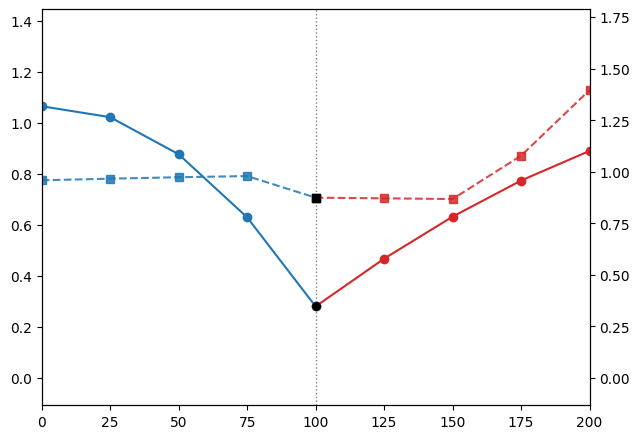

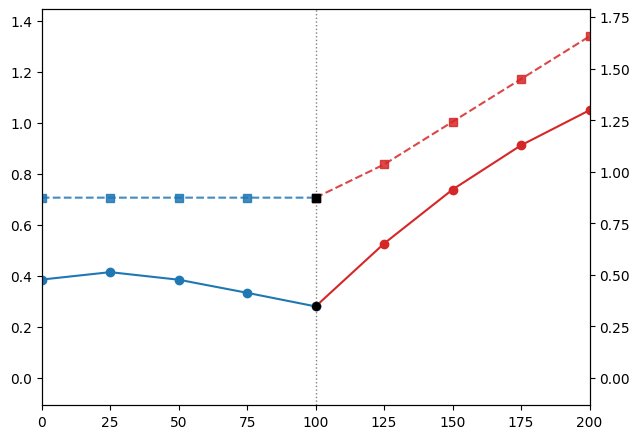

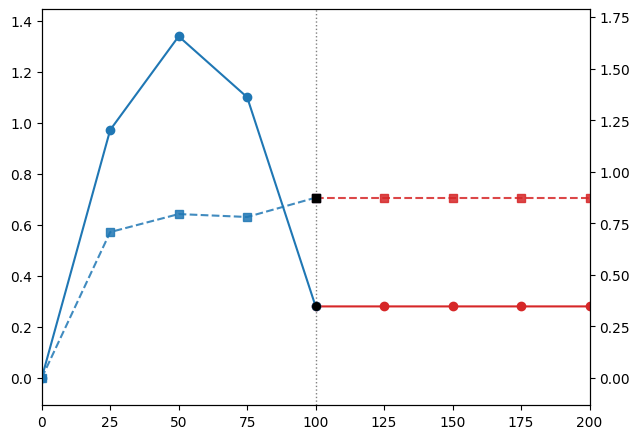

In [36]:
plot_data = moma_results.copy()

plot_data["Relative_flux_percent"] = (
    100 * plot_data["Target_flux"] /
    plot_data["Reference_flux"].abs().replace(0, np.nan)
)

plot_data["BPC"] = (
    plot_data["Biomass"] *
    plot_data["ROL_production"] * 1000
)

# WT reference BPC
WT_biomass = pfba_ROL.fluxes["Ex_biomass"]
WT_ROL = pfba_ROL.fluxes["Ex_rol"]
WT_BPC = WT_biomass * WT_ROL * 1000


# --------------------------------------------------
# 2. Prepare NADPH turnover results
# --------------------------------------------------

nadph_data = nadph_results.copy()

# Convert intervention labels such as "+100%" and "-50%"
# into the relative flux percentage (200%, 50%, etc.)
nadph_data["Intervention_percent"] = (
    nadph_data["Intervention"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

nadph_data["Relative_flux_percent"] = (
    100 + nadph_data["Intervention_percent"]
)

# WT reference NADPH turnover
WT_NADPH = nadph_data["NADPH_Turnover_WT"].dropna().iloc[0]


# --------------------------------------------------
# 3. Calculate shared y-axis limits for all plots
# --------------------------------------------------

bpc_values = np.concatenate([
    plot_data.loc[
        plot_data["Status"] == "optimal", "BPC"
    ].dropna().to_numpy(),
    np.array([WT_BPC])
])

nadph_values = np.concatenate([
    nadph_data["NADPH_Turnover_Mutant"].dropna().to_numpy(),
    np.array([WT_NADPH])
])

# Add 8% padding to each shared range
bpc_min, bpc_max = np.min(bpc_values), np.max(bpc_values)
bpc_padding = 0.08 * (bpc_max - bpc_min) if bpc_max != bpc_min else 0.1 * abs(bpc_max) + 1e-9
bpc_ylim = (bpc_min - bpc_padding, bpc_max + bpc_padding)

nadph_min, nadph_max = np.min(nadph_values), np.max(nadph_values)
nadph_padding = 0.08 * (nadph_max - nadph_min) if nadph_max != nadph_min else 0.1 * abs(nadph_max) + 1e-9
nadph_ylim = (nadph_min - nadph_padding, nadph_max + nadph_padding)


# --------------------------------------------------
# 4. Plot BPC and NADPH turnover for each reaction
# --------------------------------------------------

#RDXMAXCandidates = ['RPI','RPE','PGL','PGI','ASPTA','CTPtm','THFtm','PAtm_PP']
RDXMAXCandidates = ['RPE','PGL','CTPtm']

# Consistent colors for each intervention across plots
colors = {
    "Overexpression": "tab:red",
    "Downregulation": "tab:blue"
}

for reaction_id in RDXMAXCandidates:

    fig, ax1 = plt.subplots(figsize=(6.5, 4.5))
    ax2 = ax1.twinx()

    # ----- BPC curves from MOMA -----
    data_bpc = plot_data[
        (plot_data["Reaction"] == reaction_id) &
        (plot_data["Status"] == "optimal")
    ]

    for intervention in ["Overexpression", "Downregulation"]:

        subset = data_bpc[
            data_bpc["Intervention"] == intervention
        ].sort_values("Relative_flux_percent")

        x = np.append(
            subset["Relative_flux_percent"].to_numpy(),
            100
        )
        y = np.append(
            subset["BPC"].to_numpy(),
            WT_BPC
        )

        order = np.argsort(x)

        ax1.plot(
            x[order],
            y[order],
            color=colors[intervention],
            marker="o",
            linestyle="-",
            label=f"BPC — {intervention}"
        )

    # WT reference BPC point
    ax1.scatter(
        100, WT_BPC,
        color="black",
        marker="o",
        s=30,
        zorder=6,
        label="WT reference BPC"
    )

    # ----- NADPH turnover curves -----
    data_nadph = nadph_data[
        nadph_data["Reaction"] == reaction_id
    ].dropna(subset=["NADPH_Turnover_Mutant"])

    for intervention, sign in [
        ("Overexpression", 1),
        ("Downregulation", -1)
    ]:

        # Select positive intervention percentages for
        # overexpression and negative ones for downregulation
        if sign == 1:
            subset = data_nadph[
                data_nadph["Intervention_percent"] > 0
            ].copy()
        else:
            subset = data_nadph[
                data_nadph["Intervention_percent"] < 0
            ].copy()

        subset = subset.sort_values("Relative_flux_percent")

        x = np.append(
            subset["Relative_flux_percent"].to_numpy(),
            100
        )
        y = np.append(
            subset["NADPH_Turnover_Mutant"].to_numpy(),
            WT_NADPH
        )

        order = np.argsort(x)

        ax2.plot(
            x[order],
            y[order],
            color=colors[intervention],
            marker="s",
            linestyle="--",
            alpha=0.85,
            label=f"NADPH — {intervention}"
        )

    # WT reference NADPH point
    ax2.scatter(
        100, WT_NADPH,
        color="black",
        marker="s",
        s=30,
        zorder=6,
        label="WT reference NADPH"
    )

    # WT flux reference line
    ax1.axvline(
        100,
        color="grey",
        linestyle=":",
        linewidth=1
    )

    # Shared axes
    ax1.set_xlim(0, 200)
    ax1.set_ylim(bpc_ylim)
    ax2.set_ylim(nadph_ylim)

    
    ax1.set_ylabel("")   # Remove left y-axis title
    ax2.set_ylabel("")   # Remove right y-axis title

    ax1.grid(False)
    ax2.grid(False)

    # Combine legends from both axes
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    plt.tight_layout()
    plt.show()
    
    fig.savefig(f"results/{reaction_id}_BPC_NADPH.pdf", format="pdf", bbox_inches="tight")

In [37]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
import numpy as np
import os

# --------------------------------------------------
# 4. Plot all reactions into a single PDF
# --------------------------------------------------

RDXMAXCandidates = ['RPE', 'PGL', 'CTPtm']

# Consistent colors for each intervention
colors = {
    "Overexpression": "tab:red",
    "Downregulation": "tab:blue"
}

# Create output directory if it does not exist
os.makedirs("results", exist_ok=True)

# Single PDF containing all reaction plots
pdf_path = "results/BPC_NADPH_RDXMAX_candidates.pdf"

with PdfPages(pdf_path) as pdf:

    for reaction_id in RDXMAXCandidates:

        fig, ax1 = plt.subplots(figsize=(6.5, 4.5))
        ax2 = ax1.twinx()

        # ----- BPC curves from MOMA -----
        data_bpc = plot_data[
            (plot_data["Reaction"] == reaction_id) &
            (plot_data["Status"] == "optimal")
        ]

        for intervention in ["Overexpression", "Downregulation"]:

            subset = data_bpc[
                data_bpc["Intervention"] == intervention
            ].sort_values("Relative_flux_percent")

            x = np.append(
                subset["Relative_flux_percent"].to_numpy(),
                100
            )

            y = np.append(
                subset["BPC"].to_numpy(),
                WT_BPC
            )

            order = np.argsort(x)

            ax1.plot(
                x[order],
                y[order],
                color=colors[intervention],
                marker="o",
                linestyle="-"
            )

        # WT reference BPC point
        ax1.scatter(
            100,
            WT_BPC,
            color="black",
            marker="o",
            s=30,
            zorder=6
        )

        # ----- NADPH turnover curves -----
        data_nadph = nadph_data[
            nadph_data["Reaction"] == reaction_id
        ].dropna(subset=["NADPH_Turnover_Mutant"])

        for intervention, sign in [
            ("Overexpression", 1),
            ("Downregulation", -1)
        ]:

            # Select positive or negative interventions
            if sign == 1:
                subset = data_nadph[
                    data_nadph["Intervention_percent"] > 0
                ].copy()
            else:
                subset = data_nadph[
                    data_nadph["Intervention_percent"] < 0
                ].copy()

            subset = subset.sort_values("Relative_flux_percent")

            x = np.append(
                subset["Relative_flux_percent"].to_numpy(),
                100
            )

            y = np.append(
                subset["NADPH_Turnover_Mutant"].to_numpy(),
                WT_NADPH
            )

            order = np.argsort(x)

            ax2.plot(
                x[order],
                y[order],
                color=colors[intervention],
                marker="s",
                linestyle="--",
                alpha=0.85
            )

        # WT reference NADPH point
        ax2.scatter(
            100,
            WT_NADPH,
            color="black",
            marker="s",
            s=30,
            zorder=6
        )

        # ----- Reference line and axes -----
        ax1.axvline(
            100,
            color="grey",
            linestyle=":",
            linewidth=1
        )

        # Shared axis limits
        ax1.set_xlim(0, 200)
        ax1.set_ylim(bpc_ylim)
        ax2.set_ylim(nadph_ylim)

        # Keep reaction title
        ax1.set_title(reaction_id)

        # Remove all axis titles
        ax1.set_xlabel("")
        ax1.set_ylabel("")
        ax2.set_ylabel("")

        # Remove legends
        legend1 = ax1.get_legend()
        if legend1 is not None:
            legend1.remove()

        legend2 = ax2.get_legend()
        if legend2 is not None:
            legend2.remove()

        # Remove gridlines
        ax1.grid(False)
        ax2.grid(False)

        # Adjust layout and save one page per reaction
        fig.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

print(f"All plots exported to: {pdf_path}")

All plots exported to: results/BPC_NADPH_RDXMAX_candidates.pdf
